In [1]:
import numpy as np
%matplotlib inline
import matplotlib.pyplot as plt
import matplotlib.colors as col
from astropy.io import fits
from astropy.wcs import WCS
import astropy.units as u
from mpl_toolkits.axes_grid1 import make_axes_locatable
import matplotlib.axes as maxes
from spectral_cube import SpectralCube
from astropy.io import fits
import pandas as pd
#from scipy.stats import gaussian_kde

# Numpy Approach

In [15]:
## This is the code David used to import the data, it stores them in an array and gets
## the header data into the hx, hy variables. The setting to zero commands were given by
## David. I flatten these at the end so we can plot them and analyse them more easily.

xaxis, hx = fits.getdata('G300-310-12CO_giantcube_trim2.fit', 0, header=True, view=np.ndarray)
max_x = xaxis.max(axis=0)  
max_x[np.isnan(max_x)] = 0
yaxis, hy = fits.getdata('G300-310-13CO_giantcube_2trim.fit', 0, header=True)
max_y= yaxis.max(axis=0)
max_y[np.isnan(max_y)] = 0
max_x1=np.ndarray.flatten(max_x)
max_y1=np.ndarray.flatten(max_y)

FileNotFoundError: [Errno 2] No such file or directory: 'G300-310-12CO_giantcube_trim2.fit'

In [31]:
## I took this out because it's been giving me trouble but it agrees with the other numpys

zaxis, hz = fits.getdata('colte_Tex.fits', 0, header=True)
max_z=zaxis.max(axis=0)
max_z[np.isnan(max_z)] = 0
#max_z1=np.ndarray.flatten(max_z)

In [ ]:
## 05/12 14:38 KT
## This works but tex is still all zeros. I will try dataframes and then kappa 
j=0
l=len(max_y1)
y1_nonzero=np.zeros(l)
x1_nonzero=np.zeros(l)
z1_nonzero=np.zeros(l)
#indices=np.zeros(len(max_y1))
for i in range(l):
    if max_y1[i]!=0:
        y1_nonzero[j]=max_y1[i]
        x1_nonzero[j]=max_x1[i]
        z1_nonzero[j]=max_z1[i]
      #  indices[j]=i
        j=j+1
y1_nonzero=y1_nonzero[:j]
x1_nonzero=x1_nonzero[:j]
z1_nonzero=z1_nonzero[:j]

# Dataframe Approach

In [16]:
## This looks like it can get it into a dataframe without NaNs. It also looks
## wildly bigger so I'll try to do the same with the others.
## Edit 5/12 15:55 Ayo this worked

## 12/12/23 12:32 KT
## After today's meeting I am going to follow the instructions from 7/12 email. 

#tex_np = fits.open('colte_Tex0.fit') # This is the non-Nan version thanks to kappa nomagic
tex_np = fits.open('CODLE_Tex_COHRS_FUGIN_G35_32_10_CO12_SNR3_25arcsec.fits')
tex_np=tex_np[0].data

names = ['x', 'y', 'v']
index = pd.MultiIndex.from_product([range(s)for s in tex_np.shape], names=names)
df_tex = pd.DataFrame({'tex_np': tex_np.flatten()}, index=index)['tex_np']

#x_np = fits.open('G300-310-12CO_giantcube_trim2.fit')
x_np = fits.open('COHRS_12CO_G35_trim_399_2kms_25arcsec.fit')
x_np=x_np[0].data

index = pd.MultiIndex.from_product([range(s)for s in x_np.shape], names=names)
df_x = pd.DataFrame({'x_np': x_np.flatten()}, index=index)['x_np']

#y_np = fits.open('G300-310-13CO_giantcube_2trim.fit')
y_np = fits.open('CHIMPS_13CO_G35_trim_399_2kms_25arcsec.fit')
y_np=y_np[0].data

index = pd.MultiIndex.from_product([range(s)for s in y_np.shape], names=names)
df_y = pd.DataFrame({'y_np': y_np.flatten()}, index=index)['y_np']

#z_np = fits.open('G300-310-C18O_giantcube_2trim.fit')
z_np = fits.open('CHIMPS_C18O_G35_2kms_25arcsec.fit')
z_np=z_np[0].data

index = pd.MultiIndex.from_product([range(s)for s in z_np.shape], names=names)
df_z = pd.DataFrame({'z_np': z_np.flatten()}, index=index)['z_np']

#tau_np = fits.open('colte_Tau130.fit') \
tau_np = fits.open('CODLE_COHRS_G35_J32_Tau1318_R65_SNR3_NOmasked_trimmed_2kms_25arcsec_alt_maximum.fits') 
tau_np=tau_np[0].data

tau_np_2 = fits.open('CODLE_COHRS_G35_J32_Tau1213_R85_SNR3_NOmasked_trimmed_2kms_25arcsec_alt_maximum.fits') 
tau_np_2=tau_np_2[0].data

index = pd.MultiIndex.from_product([range(s)for s in tau_np.shape], names=names)
df_tau= pd.DataFrame({'tau_np': tau_np.flatten()}, index=index)['tau_np']

index = pd.MultiIndex.from_product([range(s)for s in tau_np_2.shape], names=names)
df_tau_2= pd.DataFrame({'tau_np_2': tau_np_2.flatten()}, index=index)['tau_np_2']

n_np = fits.open('CODLE_N13CO_CHIMPS_FUGIN_G35_32_10_SNR3_25arcsec.fits') 
n_np=n_np[0].data

index = pd.MultiIndex.from_product([range(s)for s in n_np.shape], names=names)
df_n= pd.DataFrame({'n_np': n_np.flatten()}, index=index)['n_np']

In [17]:
x_ser=df_x.to_numpy()
y_ser=df_y.to_numpy()
z_ser=df_z.to_numpy()
tex_ser=df_tex.to_numpy()
tau_ser=df_tau.to_numpy()
tau_ser_2=df_tau_2.to_numpy()
n_ser=df_n.to_numpy()
# Tau 2 in this situation is the copy, so snr=3.

In [18]:
j=0
l=len(tau_ser)
#l=len(z_ser)

## KT 15/12 15:21
## This stupid stuff is only used for the binary stuff of David's suggestion 14/12.
x_temp=np.zeros(l)
x_temp[:x_ser.shape[0]] = x_ser


y1_nonzero=np.zeros(l)
x1_nonzero=np.zeros(l)
z1_nonzero=np.zeros(l)
tex_nonzero=np.zeros(l)
tau_nonzero=np.zeros(l)
tau_nonzero_2=np.zeros(l)
n_nonzero=np.zeros(l)

for i in range(l):
    if y_ser[i]!=0:
    #if z_ser[i]!=0:
        y1_nonzero[j]=y_ser[i]
        x1_nonzero[j]=x_ser[i]
        #x1_nonzero[j]=x_temp[i]
        z1_nonzero[j]=z_ser[i]
        tex_nonzero[j]=tex_ser[i]
        tau_nonzero[j]=tau_ser[i]
        tau_nonzero_2[j]=tau_ser_2[i]
        n_nonzero[j]=n_ser[i]
        j=j+1
y1_nonzero=y1_nonzero[:j]
x1_nonzero=x1_nonzero[:j]
z1_nonzero=z1_nonzero[:j]
tex_nonzero=tex_nonzero[:j]
tau_nonzero=tau_nonzero[:j]
tau_nonzero_2=tau_nonzero_2[:j]
n_nonzero=n_nonzero[:j]

In [33]:
mask1 = np.isfinite(x1_nonzero/y1_nonzero) & np.isfinite(tau_nonzero) & np.isfinite(tau_nonzero_2)
mask2 = np.isfinite(y1_nonzero/z1_nonzero) & np.isfinite(tau_nonzero) & np.isfinite(tau_nonzero_2)

x_filtered = (x1_nonzero/y1_nonzero)[mask1] # 12/13 brightness temperature
y_filtered = (y1_nonzero/z1_nonzero)[mask2 ]# 13/18 brightness temperature

tau13_filtered1 = tau_nonzero[mask1] # Tau1318, compare with x filtered
tau13_filtered2 = tau_nonzero[mask2] # Tau1318, compare with y filtered

tau12_filtered1 = tau_nonzero_2[mask1] # Tau1318, compare with x filtered
tau12_filtered2 = tau_nonzero_2[mask2] # Tau1318, compare with y filtered

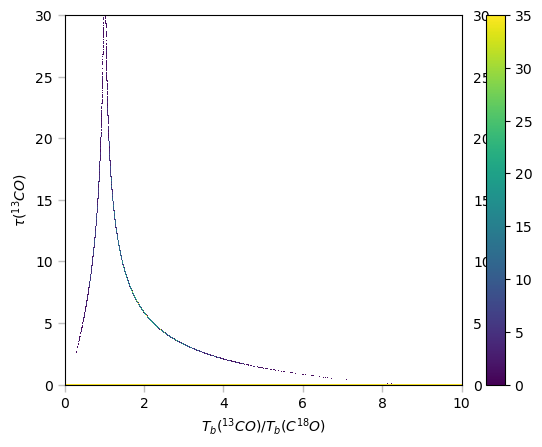

In [35]:
## 7/12 16:43 KT
## This will try to calculate point density so it can plot with density
## shading. David sent me a stackexchange on Teams and I'll be using that.
## https://stackoverflow.com/questions/20105364/how-can-i-make-a-scatter-plot-colored-by-density

## 8/12 15:51 KT
## After trying to run that abomination for 5 hours I decided to look at something else. 


import datashader as ds
from datashader.mpl_ext import dsshow


def using_datashader(ax, x, y):

    df = pd.DataFrame(dict(x=x, y=y))
    dsartist = dsshow(
        df,
        ds.Point("x", "y"),
        ds.count(),
        vmin=0,
        vmax=35,
        norm="linear",
        aspect="auto",
        ax=ax,
    )

    plt.colorbar(dsartist)
    
 fig, ax = plt.subplots()
#ax.plot(x1_nonzero/y1_nonzero, tau_nonzero, 'b.', ms=5, mfc='b', linestyle='None') # Comment this out to get density
using_datashader(ax, x_filtered, tau12_filtered1)
ax.set_xlim(0, 10)
ax.set_ylim(0, 30)
ax.tick_params(axis='y', which='both', labelleft='on', labelright='off')
ax.tick_params(axis='x', which='major', length=5, width=1., color='silver')
ax.tick_params(axis='y', which='major', length=5, width=1., color='silver')
ax.tick_params(axis='x', which='minor', width=1.)
ax.tick_params(axis='y', which='minor', width=1.)
ax.yaxis.set_label_position('left')
ax.set_xlabel(r'$T_b(^{13}CO)/T_b(C^{18}O)$')
ax.set_ylabel(r'$\tau(^{13}CO)$')
plt.show()
#fig

In [70]:
fig.savefig('COHRS_G35_colte_13_18vsTau', dpi=300, bbox_inches='tight')

# Plot

In [12]:
fig = plt.figure(figsize=(3.5, 3.5))

<Figure size 350x350 with 0 Axes>

In [13]:
ax = fig.add_subplot(111)

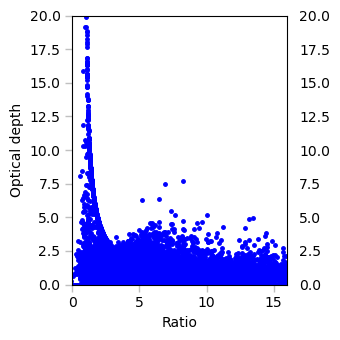

In [15]:
ax.plot(y_filtered, tau_filtered2, 'b.', ms=5, mfc='b', linestyle='None')
ax.set_xlim(0, 16)
ax.set_ylim(0, 20)
ax.tick_params(axis='y', which='both', labelleft='on', labelright='off')
ax.tick_params(axis='x', which='major', length=5, width=1., color='silver')
ax.tick_params(axis='y', which='major', length=5, width=1., color='silver')
ax.tick_params(axis='x', which='minor', width=1.)
ax.tick_params(axis='y', which='minor', width=1.)
ax.yaxis.set_label_position('left')
ax.set_xlabel(r'Ratio')
ax.set_ylabel(r'Optical depth')
fig.tight_layout()
fig

In [42]:
#fig.savefig('Tau_temp.pdf', dpi=300, bbox_inches='tight')
#fig.savefig('12_13_tau.png', dpi=300, bbox_inches='tight')

In [43]:
#ax.plot(pd.ravel(xaxis),np.ravel(yaxis))
ax.plot(x_np.ravel(),y_np.ravel())

/var/folders/my/spqrhq7n74bcr2n7xfhc9hhr0000gp/T/ipykernel_6667/2123264403.py:3: UserWarning: Matplotlib is currently using module://matplotlib_inline.backend_inline, which is a non-GUI backend, so cannot show the figure.
  fig.show()


# Useless testing playground

In [15]:
#max_x.max(axis=1)

In [67]:
#np.argmax(max_x)

In [68]:
#max_x.shape

In [154]:
df=df[115][195]
data_df.max()

21.179083

In [155]:
np.where(~np.isnan(df))

(array([   46313,   361435,   401661, ..., 94829929, 94857960, 94877778]),)

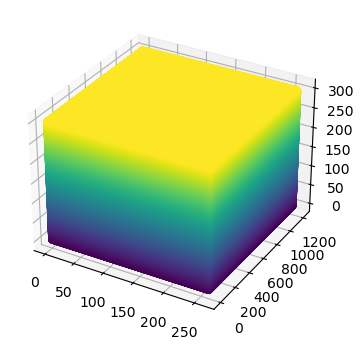

In [171]:
## This plots stuff. Use datanp, because it need arrays. Mostly this
## serves to show that datanp (Excitation temperature) is NOT a bunch
## of NaNs so SHUT UP NUMPY.

plt.rcParams["figure.figsize"] = [7.00, 3.50]
plt.rcParams["figure.autolayout"] = True
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')
z, x, y = datanp.nonzero()
ax.scatter(x, y, z, c=z, alpha=1)
plt.show()

In [36]:
print(max_x.shape,max_y.size, df_tex.size)

(263, 1213) 319019 96024719


In [135]:
z_ser.max()

21.179083

In [137]:
df_tex.max()

21.179083

In [226]:
n_nonzero.max()

2.2411777153171456e+16

In [17]:
type(x_np.ravel())
## This is the command given after the plot, it doesn't run if you only use the dataframe approach

numpy.ndarray

In [18]:
type(np.ravel(xaxis))
## Is this the equivalent command for dataframes?

numpy.ndarray

In [42]:
print(np.array_equal(np.ravel(xaxis), x_np.ravel()))
## Yes it is

False


In [49]:
len(x_temp)

92834529

In [23]:
hx

SIMPLE  =                    T / file does conform to FITS standard             
BITPIX  =                  -32 / number of bits per data pixel                  
NAXIS   =                    3 / number of data axes                            
NAXIS1  =                 1213 / length of data axis 1                          
NAXIS2  =                  263 / length of data axis 2                          
NAXIS3  =                  301 / length of data axis 3                          
EXTEND  =                    T / FITS dataset may contain extensions            
COMMENT   FITS (Flexible Image Transport System) format is defined in 'Astronomy
COMMENT   and Astrophysics', volume 376, page 359; bibcode: 2001A&A...376..359H 
LBOUND1 =                    1 / Pixel origin along axis 1                      
LBOUND2 =                    1 / Pixel origin along axis 2                      
LBOUND3 =                  496 / Pixel origin along axis 3                      
BUNIT   = 'K       '        

In [15]:
from colte.LTE import *
import pkg_resources
import json

In [16]:
DATA_PATH = pkg_resources.resource_filename('colte', 'data/')
DATA_PATH

'/Users/kyriakos.trakakis/COLTE/colte/data/'

In [17]:
nu_12 = get_freq(f'{DATA_PATH}/co.dat', 1)
nu_12

<Quantity 115.2712 GHz>

In [18]:
nu_13 = get_freq(f'{DATA_PATH}/13co.dat', 1)
nu_13

<Quantity 110.201355 GHz>

In [19]:
params = json.loads(open('defaultparams.json').read())
data_in_12CO = params['data_in_12CO']
fits.getdata(data_in_12CO)

array([[[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]],

       [[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]],

       [[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]],

       ...,

       [[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan

In [20]:
Tex_mode = params['Tex_mode']
Tex_mode

1

In [21]:
data_in_13CO = params['data_in_13CO']
hdr = fits.getheader(data_in_13CO)
wcs = WCS(hdr).celestial

In [23]:
CO13 = fits.getdata(data_in_13CO) * u.K
testplane = np.where(CO13 == np.nanmax(CO13))[0][0]
vax = vaxis(hdr)

In [26]:
np.shape(CO13)

(191, 668, 492)

In [10]:
vax

<Quantity [-1.49999943e+05, -1.48999943e+05, -1.47999943e+05,
           -1.46999943e+05, -1.45999943e+05, -1.44999943e+05,
           -1.43999943e+05, -1.42999943e+05, -1.41999943e+05,
           -1.40999943e+05, -1.39999943e+05, -1.38999943e+05,
           -1.37999943e+05, -1.36999943e+05, -1.35999943e+05,
           -1.34999943e+05, -1.33999943e+05, -1.32999943e+05,
           -1.31999943e+05, -1.30999943e+05, -1.29999943e+05,
           -1.28999943e+05, -1.27999943e+05, -1.26999943e+05,
           -1.25999943e+05, -1.24999943e+05, -1.23999943e+05,
           -1.22999943e+05, -1.21999943e+05, -1.20999943e+05,
           -1.19999943e+05, -1.18999943e+05, -1.17999943e+05,
           -1.16999943e+05, -1.15999943e+05, -1.14999943e+05,
           -1.13999943e+05, -1.12999943e+05, -1.11999943e+05,
           -1.10999943e+05, -1.09999943e+05, -1.08999943e+05,
           -1.07999943e+05, -1.06999943e+05, -1.05999943e+05,
           -1.04999943e+05, -1.03999943e+05, -1.02999943e+05,
        

In [11]:
params['single_Tex']

15.0

In [12]:
params['fill_method']

'rescale'

# Trying to understand filling by interpolation

In [13]:
## Define everything so that we won't have to later

params = json.loads(open('defaultparams.json').read())
    
data_in_12CO = params['data_in_12CO']
data_in_13CO = params['data_in_13CO']
data_in_C18O = params['data_in_C18O']

data_out = params['data_out']

snrlim12 = params['snrlim12']
snrlim13 = params['snrlim13']
snrlim18 = params['snrlim18']

Tex_mode = params['Tex_mode']
single_Tex = params['single_Tex'] * u.K

Tau_mode = params['Tau_mode']
R1318 = params['R1318']
single_Tau = params['single_Tau']
fill_method = params['fill_method']

transition = params['transition']
J_up, J_lo = np.int32(transition.split('-'))

plot_testplane = params['plot_results']
Tbg = 2.7 * u.K


global DATA_PATH
DATA_PATH = pkg_resources.resource_filename('colte', 'data/')
nu_12 = get_freq(f'{DATA_PATH}/co.dat', J_up)
nu_13 = get_freq(f'{DATA_PATH}/13co.dat', J_up)
nu_18 = get_freq(f'{DATA_PATH}/c18o.dat', J_up)

    # ===== Load in data cubes =====
hdr = fits.getheader(data_in_13CO)
wcs = WCS(hdr).celestial
CO12 = fits.getdata(data_in_12CO) * u.K
CO13 = fits.getdata(data_in_13CO) * u.K
CO18 = fits.getdata(data_in_C18O) * u.K

    # Identify the brightest 13CO plane for figures
testplane = np.where(CO13 == np.nanmax(CO13))[0][0]
vax = vaxis(hdr)
dv = (np.abs(hdr['CDELT3']) * u.Unit(hdr['CUNIT3'])).to('km/s')
    
    # ======= Mask cubes based on RMS maps =========
    # Root Mean Square values for the cubes
RMS12 = get_rms_map(CO12)
RMS13 = get_rms_map(CO13)
RMS18 = get_rms_map(CO18)

    # SNR is values over RMS, we know this
SNR12 = CO12 / RMS12[np.newaxis, :, :]
SNR13 = CO13 / RMS13[np.newaxis, :, :]
SNR18 = CO18 / RMS18[np.newaxis, :, :]
    
    # This is simple enough
CO12[SNR12 < snrlim12] = np.nan
CO13[SNR13 < snrlim13] = np.nan
CO18[SNR18 < snrlim18] = np.nan

/Users/kyriakos.trakakis/anaconda3/lib/python3.11/site-packages/astropy/units/quantity.py:611: RuntimeWarning: divide by zero encountered in divide
  result = super().__array_ufunc__(function, method, *arrays, **kwargs)
/Users/kyriakos.trakakis/anaconda3/lib/python3.11/site-packages/astropy/units/quantity.py:611: RuntimeWarning: invalid value encountered in divide
  result = super().__array_ufunc__(function, method, *arrays, **kwargs)


In [14]:
Tex_12 = get_Tex(CO12, nu_12)
Tex_13 = get_Tex(CO13, nu_13)
Tex_max = np.maximum(Tex_12, Tex_13)

In [15]:
mask = (1 * CO13 > CO12)
dilated_mask = binary_dilate_cube(mask, iterations=1)

In [16]:
Tau_13 = get_Tau(CO13, nu_13, Tex_max)
Tau_18 = get_Tau(CO18, nu_18, Tex_max)

/Users/kyriakos.trakakis/anaconda3/lib/python3.11/site-packages/astropy/units/quantity.py:611: RuntimeWarning: divide by zero encountered in log
  result = super().__array_ufunc__(function, method, *arrays, **kwargs)
/Users/kyriakos.trakakis/anaconda3/lib/python3.11/site-packages/astropy/units/quantity.py:611: RuntimeWarning: invalid value encountered in log
  result = super().__array_ufunc__(function, method, *arrays, **kwargs)
/Users/kyriakos.trakakis/anaconda3/lib/python3.11/site-packages/astropy/units/quantity.py:611: RuntimeWarning: divide by zero encountered in reciprocal
  result = super().__array_ufunc__(function, method, *arrays, **kwargs)
/Users/kyriakos.trakakis/anaconda3/lib/python3.11/site-packages/astropy/units/quantity.py:611: RuntimeWarning: invalid value encountered in multiply
  result = super().__array_ufunc__(function, method, *arrays, **kwargs)


In [17]:
Tau_13_18 = Tau_13.copy()
Tau_13_18[dilated_mask == 1] = np.nan
Tau_13_18[~np.isnan(Tau_18)] = R1318 * Tau_18[~np.isnan(Tau_18)]

In [18]:
## Here comes the shit dodododo
interpolated = Tau_13_18.copy()

In [19]:
if 'kwargs' not in locals():
    kwargs = {}

In [21]:
for pp, plane in enumerate(tqdm(interpolated)):
    if len(np.where(~np.isnan(plane))[0]) >= 4:
        xindices = np.arange(0, plane.shape[1])
        yindices = np.arange(0, plane.shape[0])
        
        # Mask invalid values
        plane = np.ma.masked_invalid(plane)
        xx, yy = np.meshgrid(xindices, yindices)
        
        # Get only the valid values
        x1 = xx[~plane.mask]
        y1 = yy[~plane.mask]
        newplane = plane[~plane.mask]
        
        # Perform the interpolation. (x1,y1) are the coordinates of the known data points, newplane.ravel 
        # contains the corresponding values and (xx,yy) the points at which to interpolate the data.
        # Not too sure what that means.
        newplane = interpolate.griddata((x1, y1), newplane.ravel(),
                                    (xx, yy), **kwargs)  
        
        # Mask to only include values with not-nan value in nanmask cube
        newplane[np.isnan(CO13[pp].value)] = np.nan   
        
        # Assign plane to output cube
        interpolated[pp] = newplane   

100%|█████████████████████████████████████████| 301/301 [13:47<00:00,  2.75s/it]


In [22]:
## xx and yy are just 263 by 1213 arrays. xindices and yindices are just 1D arrays of size 1213 and 263
print(np.shape(yy),np.size(yy))

(263, 1213) 319019


In [23]:
## Only a few values are masked, 310
np.size(yy)-np.size(y1)

310

In [24]:
np.size(newplane.ravel())

319019

In [25]:
Tau_13_18_fill = fill_cube_interp(Tau_13_18, CO13, method="linear")

100%|█████████████████████████████████████████| 301/301 [13:58<00:00,  2.78s/it]


In [28]:
masked_cube = CO13.copy()
masked_cube[np.isnan(mask)] = np.nan

In [31]:
np.shape(masked_cube)[0]

301

In [51]:
y_np

array([[[0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        ...,
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.]],

       [[0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        ...,
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.]],

       [[0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        ...,
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.]],

       ...,

       [[0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        ...,
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0.

In [131]:
from sklearn.linear_model import LinearRegression
model = LinearRegression()

tau1=pd.DataFrame(tau_nonzero)
tau2=pd.DataFrame(tau_nonzero_2)

tau1.dropna(inplace=True)  # Remove rows with NaN values
tau2.dropna(inplace=True)  # Remove rows with NaN values

# Fit the model to the data
model.fit(tau1,tau2)

# Print the coefficients
print('Intercept:', model.intercept_)
print('Slope:', model.coef_[0])

Intercept: [6.83120227e-13]
Slope: [1.]


In [151]:
j=0
for i in range(tau1.size):
    if ((tau1.iloc[i]-tau2.iloc[i])[0]==0):
        #print(i)
        j=j+1
print(j)

667657


In [132]:
tau1.shape

(667657, 1)

In [146]:
(tau1.iloc[1]-tau2.iloc[1])[0]

0.0

In [148]:
tau1.iloc[0]

0   -0.0
Name: 61791, dtype: float64

In [6]:
import os
master_path = os.getcwd()
scimes_path=master_path+'/scimes/scimes'

In [7]:
os.listdir(scimes_path)

['conftest.py',
 '.DS_Store',
 'version.py',
 '_astropy_init.py',
 'plotting.py',
 '__init__.py',
 '__pycache__',
 'orion_12CO.fits',
 'scimes.py',
 '.ipynb_checkpoints',
 'old_spectral_embedding.py',
 'orion2scimes.py']

In [8]:
import sys
sys.path.append('scimes_path')

In [9]:
from scimes.scimes.scimes import mat_smooth

In [10]:
from astropy.io import fits
hdu = fits.open('orion_12CO.fits')[0]
data = hdu.data
hd = hdu.header

In [11]:
>>> from astrodendro import Dendrogram
>>> d = Dendrogram.compute(data)

In [12]:
sigma = 0.3 #K, noise level
ppb = 1.3 #pixels/beam
from astrodendro import Dendrogram
d = Dendrogram.compute(data, min_value=sigma, min_delta=2*sigma, min_npix=3*ppb)

In [13]:
try:
    # Attempt to import Counter from collections
    from collections import Counter
    
    # If the import succeeds, create a Counter object and count occurrences
    my_list = ['a', 'b', 'c', 'a', 'b', 'a']
    counter = Counter(my_list)
    print("Counter imported successfully!")
    print("Occurrences of items in the list:", counter)
except ImportError:
    # If the import fails, print an error message
    print("Failed to import Counter from collections!")

Counter imported successfully!
Occurrences of items in the list: Counter({'a': 3, 'b': 2, 'c': 1})


In [14]:
import sys
print(sys.version)
print(np.__version__)

3.11.7 | packaged by conda-forge | (main, Dec 23 2023, 14:38:07) [Clang 16.0.6 ]
1.26.3


In [15]:
from astrodendro.dendrogram import *

In [43]:
d = dendrogram.compute(data)

AttributeError: module 'astrodendro.dendrogram' has no attribute 'compute'

In [39]:
dendrogram

<module 'astrodendro.dendrogram' from '/Users/kyriakos.trakakis/COLTE/astrodendro/dendrogram.py'>

In [16]:
>>> from astrodendro import ppv_catalog
>>> from astropy import units as u
>>> metadata = {}
>>> metadata['data_unit'] = u.Jy
>>> cat = ppv_catalog(d, metadata)

Computing catalog for 1022 structures

[>                                        ] 0%
[>                                        ] 0%
[>                                        ] 0%
[>                                        ] 0%
[>                                        ] 0%
[>                                        ] 0%
[>                                        ] 0%
[>                                        ] 0%
[>                                        ] 0%
[>                                        ] 0%
[>                                        ] 1%
[>                                        ] 1%
[>                                        ] 1%
[>                                        ] 1%
[>                                        ] 1%
[>                                        ] 1%
[>                                        ] 1%
[>                                        ] 1%
[>                                        ] 1%
[>                                        ] 1%
[>                   

/Users/kyriakos.trakakis/COLTE/astrodendro/analysis.py:254: MissingMetadataWarning: vaxis (Index of velocity axis (numpy convention)) missing, defaulting to 0
  warnings.warn("{0} ({1}) missing, defaulting to {2}".format(self.key, self.description, self.default),
/Users/kyriakos.trakakis/COLTE/astrodendro/analysis.py:254: MissingMetadataWarning: vaxis (Index of velocity axis (numpy convention)) missing, defaulting to 0
  warnings.warn("{0} ({1}) missing, defaulting to {2}".format(self.key, self.description, self.default),



[=====>                                   ] 14%
[=====>                                   ] 14%
[=====>                                   ] 14%
[=====>                                   ] 14%
[=====>                                   ] 14%
[======>                                  ] 15%
[======>                                  ] 15%
[======>                                  ] 15%
[======>                                  ] 15%
[======>                                  ] 15%
[======>                                  ] 15%
[======>                                  ] 15%
[======>                                  ] 15%
[======>                                  ] 15%
[======>                                  ] 15%
[======>                                  ] 16%
[======>                                  ] 16%
[======>                                  ] 16%
[======>                                  ] 16%
[======>                                  ] 16%
[======>                               

In [18]:
from scimes.scimes.scimes import SpectralCloudstering
dclust = SpectralCloudstering(d, cat)
cloud=SpectralCloudstering()

TypeError: SpectralCloudstering.__init__() missing 1 required positional argument: 'header'

In [49]:
SpectralCloudstering

scimes.scimes.scimes.SpectralCloudstering

In [44]:
mat_smooth

<function scimes.scimes.scimes.mat_smooth(Mat, S2Nmat, s2nlim=3, scalpar=None, lscal=False)>

In [25]:
np.shape(tau_filtered1)

(11209505,)